# DS201 - Lab 2: Mạng neural tích chập

Họ tên: Trần Yến Nhi
MSSV: 23521117

## 0. Chuẩn bị

In [1]:
%cd /content
!unzip -qo DS201_Lab2.zip
%cd /content/DS201_Lab2
!pip -q install -r requirements.txt

/content
/content/DS201_Lab2


In [2]:
import torch
print(torch.cuda.is_available(), torch.cuda.get_device_name(0) if torch.cuda.is_available() else "")

True Tesla T4


In [3]:
# để runs/ và splits/ trên drive, colab bị ngắt cũng không mất kết quả
from google.colab import drive
drive.mount("/content/drive")

SAVE_DIR = "/content/drive/MyDrive/DS201_Lab2"
!mkdir -p {SAVE_DIR}/runs {SAVE_DIR}/splits
!rm -rf runs splits
!ln -s {SAVE_DIR}/runs runs
!ln -s {SAVE_DIR}/splits splits
!ls runs

Mounted at /content/drive
googlenet  lenet_max	 resnet18_compare.png  resnet50_fe
lenet_avg  resnet18_aug  resnet18_noaug        resnet50_ft


In [4]:
   !rm -rf runs/googlenet
   !ls runs

lenet_avg  resnet18_aug		 resnet18_noaug  resnet50_ft
lenet_max  resnet18_compare.png  resnet50_fe


In [5]:
# tải dataset, resize trước rồi nén lại lên drive. mấy lần sau chỉ cần giải nén từ drive
import os

DATA = "VinaFood21_256"
ZIP = SAVE_DIR + "/VinaFood21_256.zip"

if not os.path.exists(DATA):
    if os.path.exists(ZIP):
        !unzip -q {ZIP}
    else:
        !gdown 1UpZOf0XlwvB4rKpyZ35iwTA8oWHqDBbR -O VinaFood21.zip
        !unzip -q VinaFood21.zip -d raw
        src = [root for root, dirs, _ in os.walk("raw") if "train" in dirs and "test" in dirs][0]
        !python prepare_data.py --src {src} --dst {DATA}
        !zip -qr {ZIP} {DATA}
        !rm -rf raw VinaFood21.zip

In [6]:
import pandas as pd

classes = sorted(os.listdir(f"{DATA}/train"))
count = pd.DataFrame({
    "train": [len(os.listdir(f"{DATA}/train/{c}")) for c in classes],
    "test": [len(os.listdir(f"{DATA}/test/{c}")) for c in classes],
}, index=classes)
print("tổng train:", count.train.sum(), "| tổng test:", count.test.sum())
count.sort_values("train")

tổng train: 10044 | tổng test: 6682


,train,test
bap-nuong,215,143
ca-ri,258,171
banh-u,266,176
canh-khoai-mo,296,198
tau-hu,304,203
hoanh-thanh-nuoc,361,240
banh-can,363,241
bot-chien,415,276
banh-mi-chao,434,289
canh-kho-qua,436,290


In [7]:
import json
from IPython.display import Image, display


def run(name, args):
    if os.path.exists(f"runs/{name}/test_metrics.json"):
        print(name, "đã chạy rồi")
        return
    !python train.py {args} --run_name {name} --data_root {DATA}
    !python evaluate.py --run_dir runs/{name} --data_root {DATA}


def show(name):
    info = json.load(open(f"runs/{name}/info.json"))
    m = json.load(open(f"runs/{name}/test_metrics.json"))
    print(f"params {info['n_params']:,} | {info['sec_per_epoch']:.1f}s/epoch | best epoch {info['best_epoch']}")
    print(f"accuracy {m['accuracy']:.4f} | precision {m['precision']:.4f} | recall {m['recall']:.4f} | f1 {m['f1']:.4f}")
    display(Image(f"runs/{name}/loss.png", width=450))
    display(Image(f"runs/{name}/confusion_matrix.png", width=650))


def f1_table(*names):
    cols = [pd.read_csv(f"runs/{n}/per_class_f1.csv", index_col="class")["f1"].rename(n) for n in names]
    return pd.concat(cols, axis=1).sort_values(names[0])

## 1. Kiểm tra kiến trúc

In [8]:
import torch.nn as nn
from models import LeNet5, InceptionBlock, GoogLeNet, ResNet18, PretrainedResnet, count_params

lenet = LeNet5(3, 64, 21)
x = torch.zeros(1, 3, 64, 64)
for name in ["c1", "s2", "c3", "s4", "flatten", "f5", "f6", "out"]:
    if name == "flatten":
        x = x.flatten(1)
        print(name, tuple(x.shape))
        continue
    layer = getattr(lenet, name)
    x = layer(x)
    print(name, tuple(x.shape), count_params(layer))
print("tổng:", count_params(lenet))

c1 (1, 6, 64, 64) 456
s2 (1, 6, 32, 32) 0
c3 (1, 16, 28, 28) 2416
s4 (1, 16, 14, 14) 0
flatten (1, 3136)
f5 (1, 120) 376440
f6 (1, 84) 10164
out (1, 21) 1785
tổng: 391261


In [9]:
net = GoogLeNet(21)
# channel ra của mỗi Inception block = f1 + f3 + f5 + fp
tinh_tay = [64 + 128 + 32 + 32, 128 + 192 + 96 + 64,                          # b3: 2 block
            192 + 208 + 48 + 64, 160 + 224 + 64 + 64, 128 + 256 + 64 + 64,
            112 + 288 + 64 + 64, 256 + 320 + 128 + 128,                        # b4: 5 block
            256 + 320 + 128 + 128, 384 + 384 + 128 + 128]                      # b5: 2 block

x = torch.zeros(1, 3, 64, 64)
k = 0
for bname in ["b1", "b2", "b3", "b4", "b5"]:
    block = getattr(net, bname)
    for layer in block:
        x = layer(x)
        if isinstance(layer, InceptionBlock):
            print(f"  inception {k + 1}: tính tay {tinh_tay[k]}, code {x.shape[1]}, "
                  f"shape {tuple(x.shape)}, params {count_params(layer):,}")
            k += 1
    print(f"{bname} -> {tuple(x.shape)}, params {count_params(block):,}")
print("số Inception block:", k, "| tổng:", f"{count_params(net):,}", "| fc:", f"{count_params(net.fc):,}")

b1 -> (1, 64, 16, 16), params 9,536
b2 -> (1, 192, 8, 8), params 115,200
  inception 1: tính tay 256, code 256, shape (1, 256, 8, 8), params 164,064
  inception 2: tính tay 480, code 480, shape (1, 480, 8, 8), params 389,376
b3 -> (1, 480, 4, 4), params 553,440
  inception 3: tính tay 512, code 512, shape (1, 512, 4, 4), params 376,800
  inception 4: tính tay 512, code 512, shape (1, 512, 4, 4), params 449,808
  inception 5: tính tay 512, code 512, shape (1, 512, 4, 4), params 510,768
  inception 6: tính tay 528, code 528, shape (1, 528, 4, 4), params 606,080
  inception 7: tính tay 832, code 832, shape (1, 832, 4, 4), params 869,376
b4 -> (1, 832, 2, 2), params 2,812,832
  inception 8: tính tay 832, code 832, shape (1, 832, 2, 2), params 1,044,480
  inception 9: tính tay 1024, code 1024, shape (1, 1024, 2, 2), params 1,445,344
b5 -> (1, 1024), params 2,489,824
số Inception block: 9 | tổng: 6,002,357 | fc: 21,525


In [10]:
r18 = ResNet18(21)
x = torch.zeros(1, 3, 112, 112)
for name in ["stem", "layer1", "layer2", "layer3", "layer4"]:
    x = getattr(r18, name)(x)
    print(name, tuple(x.shape), count_params(getattr(r18, name)))
print("tổng:", count_params(r18))

from torchvision.models import resnet18
tv = resnet18()
tv.fc = nn.Linear(512, 21)
print("torchvision:", count_params(tv))

stem (1, 64, 28, 28) 9536
layer1 (1, 64, 28, 28) 147968
layer2 (1, 128, 14, 14) 525568
layer3 (1, 256, 7, 7) 2099712
layer4 (1, 512, 4, 4) 8393728
tổng: 11187285
torchvision: 11187285


In [11]:
fe = PretrainedResnet(21, freeze_backbone=True)
ft = PretrainedResnet(21, freeze_backbone=False)
print("feature extraction:", count_params(fe), "| học:", count_params(fe, trainable=True))
print("fine-tuning:", count_params(ft), "| học:", count_params(ft, trainable=True))
del fe, ft

config.json:   0%|          | 0.00/69.6k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  102MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/320 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/320 [00:00<?, ?it/s]

feature extraction: 23551061 | học: 43029
fine-tuning: 23551061 | học: 23551061


## Bài 1. LeNet-5

Ảnh 64x64, conv đầu 5x5 pad 2 như hình (giữ nguyên 64x64), ReLU, AvgPool2d(2, 2), Adam lr 1e-3, batch 32, 20 epoch. Sau đó đổi sang MaxPool2d, còn lại giữ nguyên.

In [12]:
run("lenet_avg", "--model lenet --pool avg")

lenet_avg đã chạy rồi


params 391,261 | 16.4s/epoch | best epoch 19
accuracy 0.3252 | precision 0.3266 | recall 0.3146 | f1 0.3043


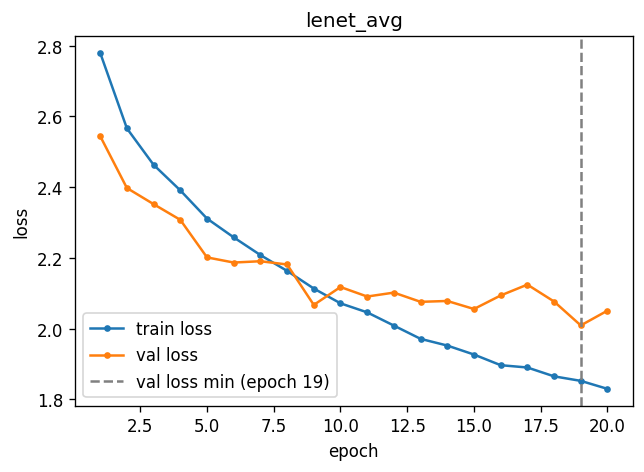

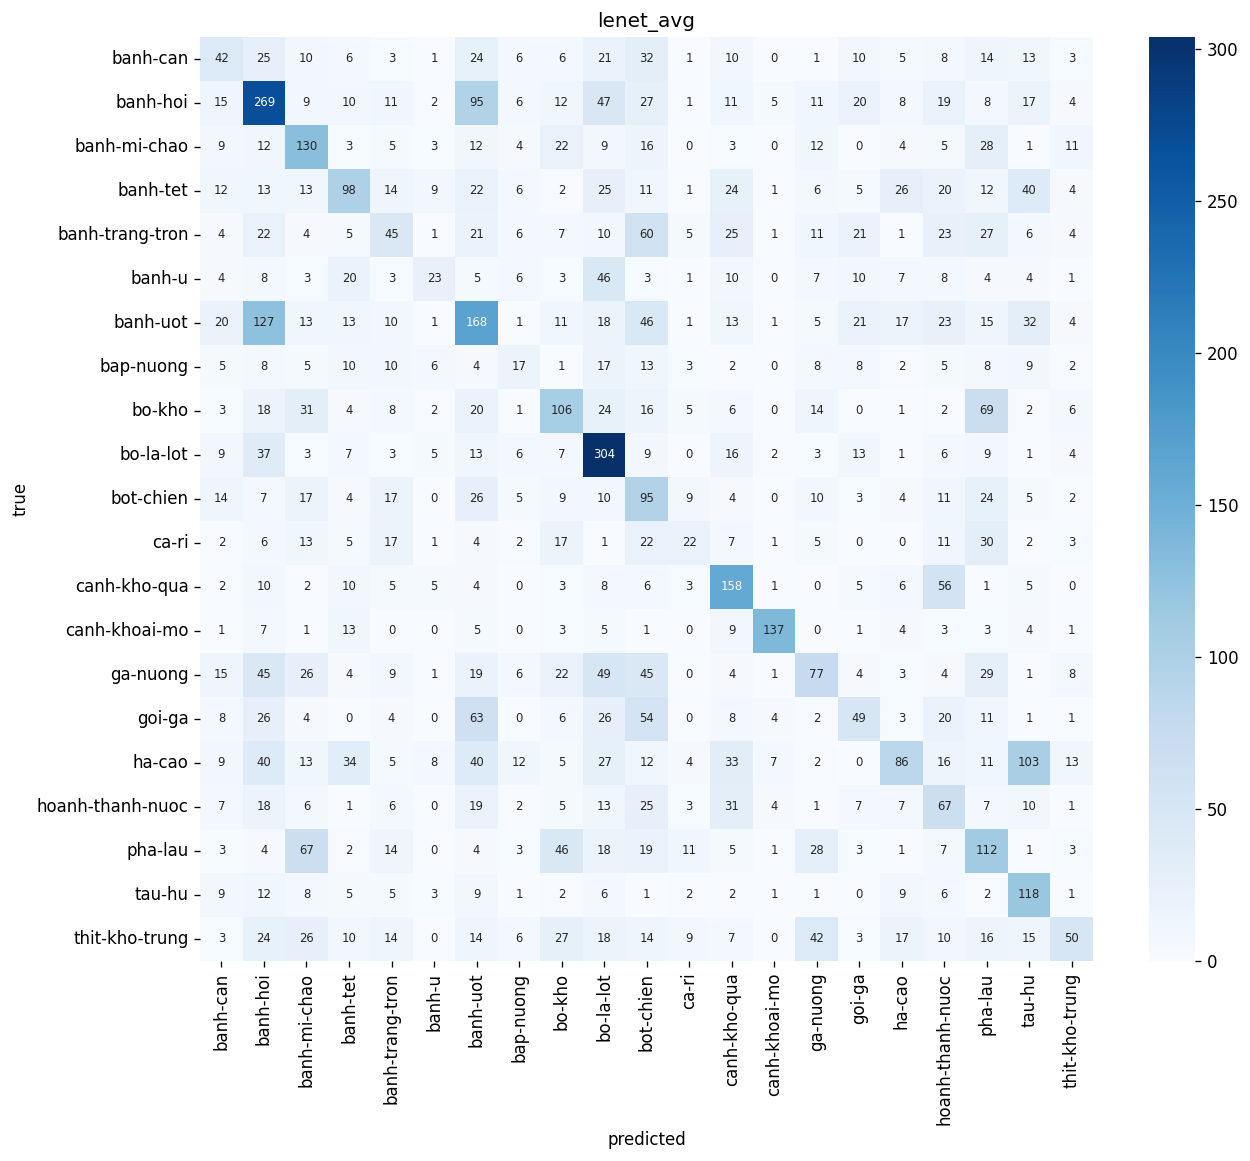

In [13]:
show("lenet_avg")

In [14]:
run("lenet_max", "--model lenet --pool max")

lenet_max đã chạy rồi


params 391,261 | 16.6s/epoch | best epoch 20
accuracy 0.3360 | precision 0.3264 | recall 0.3286 | f1 0.3127


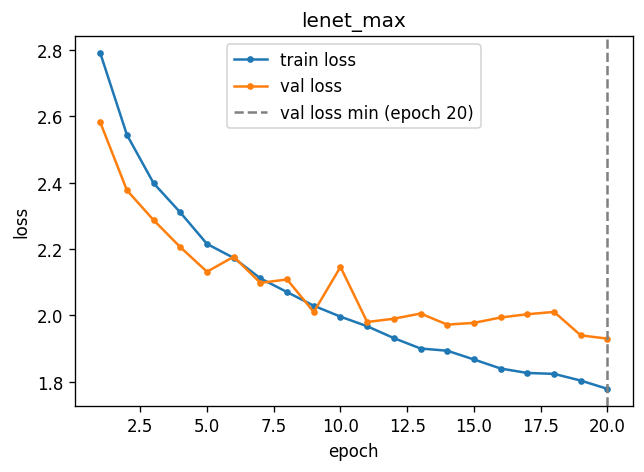

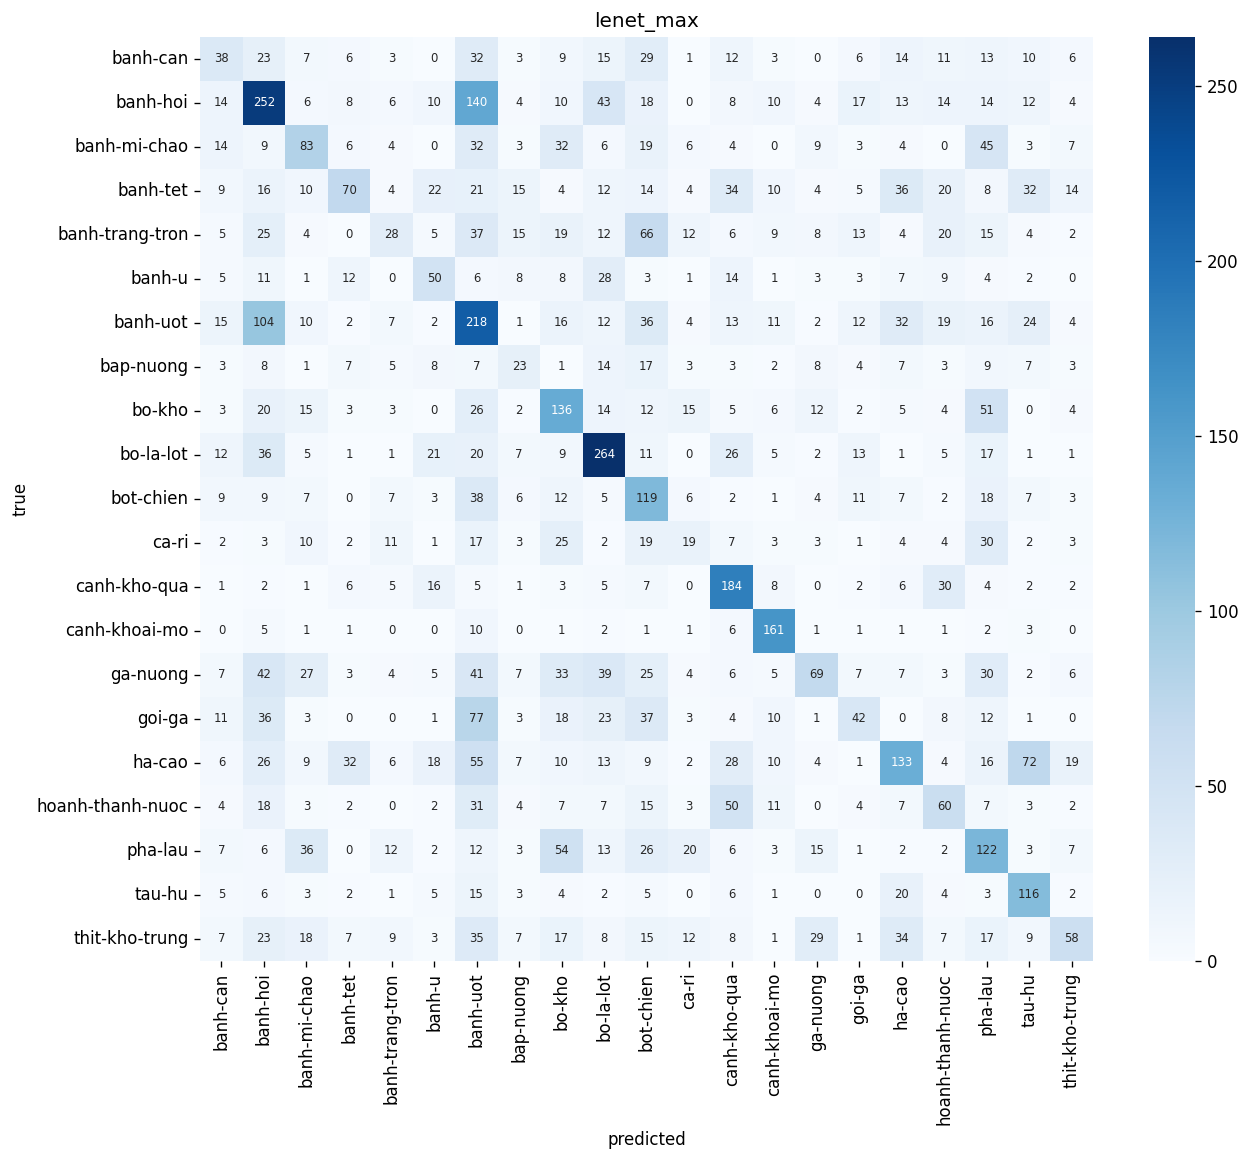

In [15]:
show("lenet_max")

In [16]:
f1_table("lenet_avg", "lenet_max")

,lenet_avg,lenet_max
class,,
bap-nuong,0.1423,0.1716
banh-trang-tron,0.1741,0.1318
ca-ri,0.1746,0.1324
banh-u,0.1862,0.2857
banh-can,0.1922,0.1818
goi-ga,0.2072,0.1913
thit-kho-trung,0.2217,0.2458
hoanh-thanh-nuoc,0.2351,0.2553
bot-chien,0.2366,0.3055


Nhận xét:
- Số tham số 391,261, đúng với tính tay: conv đầu có pad 2 nên 64 → 64 → 32 → 28 → 14, flatten 16x14x14 = 3136. F5 chiếm 376,440 (khoảng 96.2%), 2 lớp conv chỉ có 2,872. Pooling không có tham số nên đổi Avg sang Max không đổi số tham số.
- AvgPool: accuracy 0.3252, macro-F1 0.3043. MaxPool: accuracy 0.3360, macro-F1 0.3127, cao hơn khoảng 0.008 (13/21 lớp tăng). MaxPool giữ lại giá trị lớn nhất trong mỗi ô 2x2 nên giữ được cạnh, kết cấu rõ hơn, còn AvgPool lấy trung bình nên làm mờ đi. Tuy vậy chênh lệch nhỏ và em chỉ chạy 1 seed nên chưa thể khẳng định MaxPool chắc chắn tốt hơn.
- Loss: train loss giảm đều nhưng chậm, sau 20 epoch train acc mới khoảng 44% (AvgPool 43.5%, MaxPool 44.6%) → model đang underfit, LeNet quá nhỏ (2 lớp conv với 6 và 16 filter) để phân biệt 21 món từ ảnh 64x64. Val loss của bản AvgPool thấp nhất ở epoch 19 (2.009) rồi nhích lên 2.051 ở epoch 20; bản MaxPool val loss vẫn còn giảm tới epoch 20 (1.930). Hai đường train/val loss chưa tách nhau rõ → chưa overfit, train thêm epoch có thể còn tăng.
- Lớp F1 thấp nhất (AvgPool): bap-nuong 0.142, banh-trang-tron 0.174, ca-ri 0.175, banh-u 0.186, banh-can 0.192; trong đó bap-nuong, ca-ri, banh-u là 3 lớp ít ảnh train nhất (215, 258, 266 ảnh). Cao nhất là canh-khoai-mo 0.751, chắc do màu tím rất dễ nhận ra. Trên confusion matrix, nhầm nhiều nhất là banh-uot → banh-hoi (127 ảnh), ha-cao → tau-hu (103 ảnh) và banh-hoi → banh-uot (95 ảnh). banh-uot và banh-hoi đều làm từ bột gạo màu trắng, ở 64x64 nhìn gần như giống nhau; ha-cao và tau-hu cũng đều màu trắng, bề mặt mịn.

## Bài 2. GoogLeNet

Theo đúng hình trong đề: 7x7 Conv (stride 2) → 3x3 MaxPool → 1x1 Conv → 3x3 Conv → 3x3 MaxPool → 2 Inception → 3x3 MaxPool → 5 Inception → 3x3 MaxPool → 2 Inception → Global AvgPool → FC, tổng 9 Inception block, số channel lấy theo bản gốc. Ảnh 64x64 nên kích thước giảm 64 → 16 → 8 → 4 → 2 rồi qua GAP. Nối nhánh bằng `torch.cat(..., dim=1)`. Từ bài này em bật `--amp` cho nhanh, các thông số khác giữ như Bài 1.

Hình không vẽ BatchNorm, nhưng em thêm BatchNorm sau mỗi conv (giống GoogLeNet của torchvision). Lần chạy đầu em không dùng BN mà khởi tạo kaiming (fan_out): loss epoch 1 lên tới 9.25, sau 20 epoch macro-F1 chỉ 0.2948, thấp hơn cả LeNet. Nguyên nhân là ở các conv 1x1 giảm channel (ví dụ 192 → 16), khởi tạo theo fan_out cho trọng số quá lớn nên tín hiệu bị khuếch đại qua các lớp. Có BN thì đầu ra mỗi conv được chuẩn hoá lại nên mạng khoảng 22 lớp train ổn định hơn.

In [17]:
run("googlenet", "--model googlenet --amp")

googlenet | cuda | train 9040 ảnh | val 1004 ảnh
params 6,002,357 (trainable 6,002,357) | img 64 | lr 0.001 | aug True
epoch 1/20 - train loss 2.8716 acc 0.1499 - val loss 2.8083 acc 0.1653 f1 0.0726 - 28s
epoch 2/20 - train loss 2.7312 acc 0.1706 - val loss 2.5309 acc 0.2022 f1 0.1219 - 25s
epoch 3/20 - train loss 2.5769 acc 0.2090 - val loss 2.4999 acc 0.2291 f1 0.1528 - 27s
epoch 4/20 - train loss 2.4810 acc 0.2316 - val loss 2.4071 acc 0.2490 f1 0.1695 - 27s
epoch 5/20 - train loss 2.3749 acc 0.2592 - val loss 2.2662 acc 0.3078 f1 0.2459 - 26s
epoch 6/20 - train loss 2.2985 acc 0.2923 - val loss 2.3878 acc 0.2789 f1 0.2171 - 26s
epoch 7/20 - train loss 2.2220 acc 0.3114 - val loss 2.2443 acc 0.2998 f1 0.2411 - 26s
epoch 8/20 - train loss 2.1351 acc 0.3367 - val loss 2.0396 acc 0.3526 f1 0.2828 - 25s
epoch 9/20 - train loss 2.0775 acc 0.3611 - val loss 2.0635 acc 0.3606 f1 0.2966 - 25s
epoch 10/20 - train loss 1.9990 acc 0.3871 - val loss 1.9363 acc 0.4153 f1 0.3612 - 25s
epoch 11/2

params 6,002,357 | 25.5s/epoch | best epoch 19
accuracy 0.4442 | precision 0.4538 | recall 0.4210 | f1 0.4142


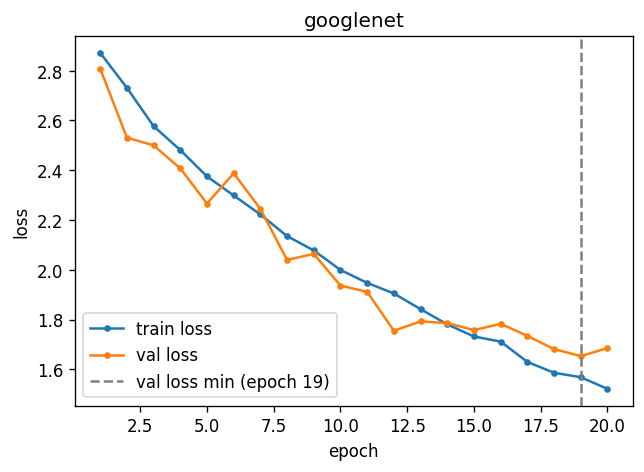

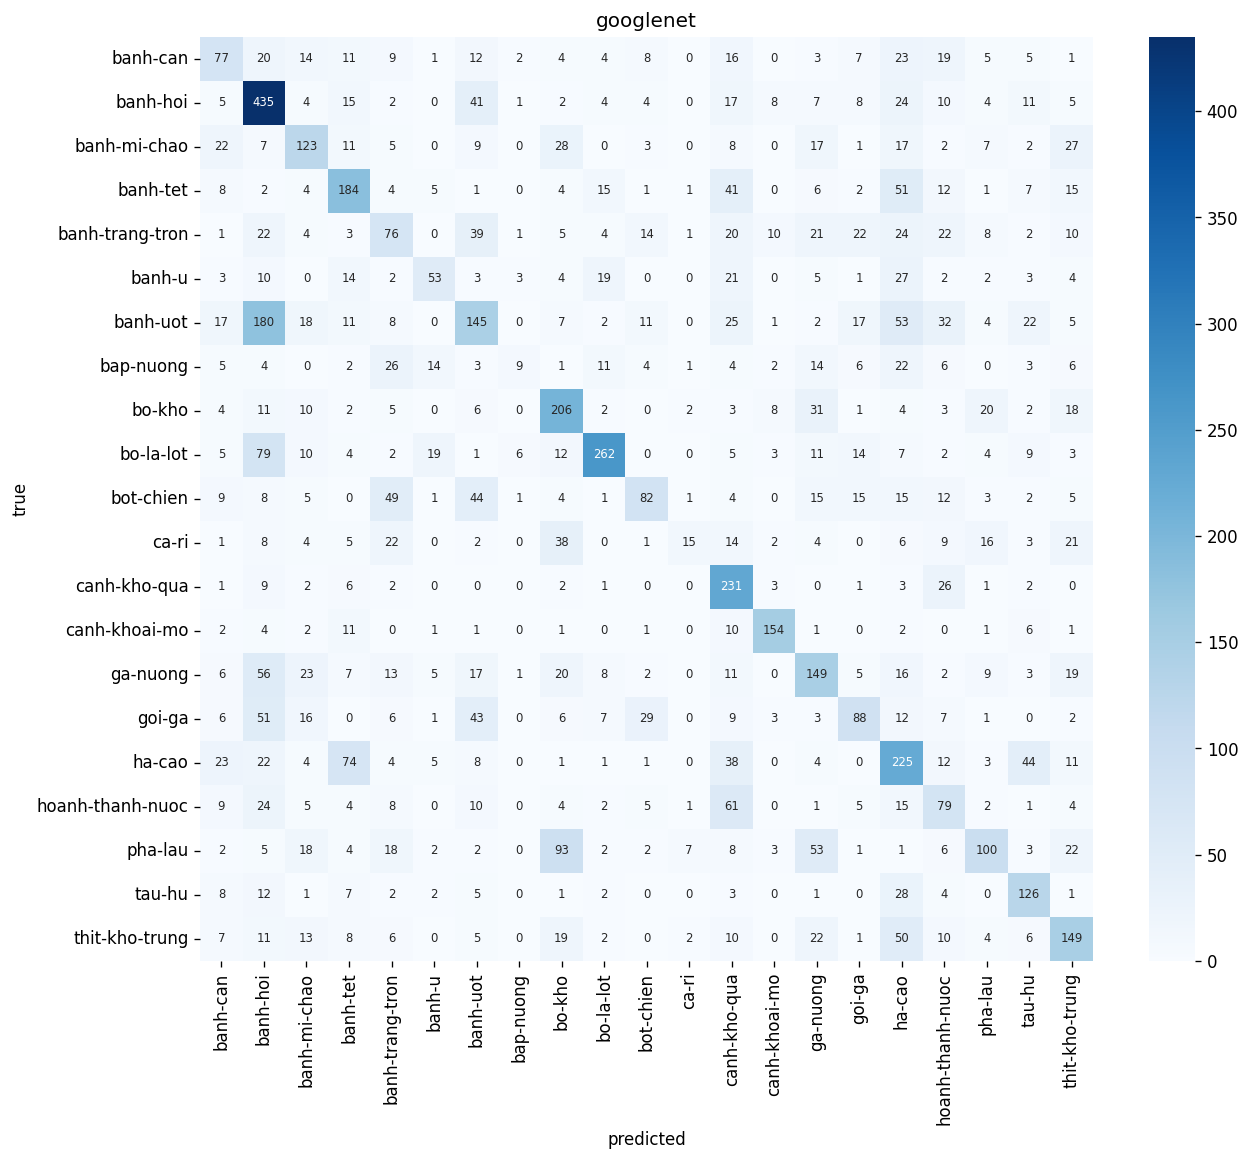

In [18]:
show("googlenet")

In [19]:
rows = []
for name in ["lenet_avg", "lenet_max", "googlenet"]:
    info = json.load(open(f"runs/{name}/info.json"))
    m = json.load(open(f"runs/{name}/test_metrics.json"))
    rows.append([name, info["n_params"], round(info["sec_per_epoch"], 1), round(m["accuracy"], 4), round(m["f1"], 4)])
pd.DataFrame(rows, columns=["model", "params", "s/epoch", "accuracy", "macro-F1"])

,model,params,s/epoch,accuracy,macro-F1
0,lenet_avg,391261,16.4,0.3252,0.3043
1,lenet_max,391261,16.6,0.3360,0.3127
2,googlenet,6002357,25.5,0.4442,0.4142


In [20]:
f1_table("googlenet", "lenet_avg")

,googlenet,lenet_avg
class,,
bap-nuong,0.1078,0.1423
ca-ri,0.1485,0.1746
banh-trang-tron,0.2630,0.1741
banh-uot,0.3030,0.2919
hoanh-thanh-nuoc,0.3056,0.2351
banh-can,0.3333,0.1922
goi-ga,0.3629,0.2072
pha-lau,0.3656,0.2828
bot-chien,0.3694,0.2366


Nhận xét:
- Channel ra của 9 block tính tay và in từ code khớp nhau: 256, 480 | 512, 512, 512, 528, 832 | 832, 1024.
- Tổng 6,002,357 tham số, gấp khoảng 15 lần LeNet (391,261), nhưng phân bố khác hẳn: 9 Inception block chiếm 5,856,096 (khoảng 97.6%), 3 lớp conv đầu 124,736, còn lớp fc chỉ có 21,525 nhờ GAP. Ngược lại ở LeNet gần như toàn bộ tham số nằm ở lớp FC đầu tiên.
- Thời gian 25.5 s/epoch so với 16.4 s/epoch của LeNet. GoogLeNet tính toán nhiều hơn LeNet rất nhiều nhưng thời gian chỉ tăng khoảng 1.5 lần, vì phần chậm nhất là đọc ảnh + augment trên 2 CPU của Colab, GPU phải chờ dữ liệu. Ở Bài 3 thấy rõ hơn: cùng ResNet-18, tắt augmentation thì từ 30.8 xuống còn 21.1 s/epoch.
- macro-F1 0.4142 so với 0.3043 của LeNet AvgPool (tăng 0.110), accuracy 0.4442 so với 0.3252. 19/21 lớp tăng, chỉ có bap-nuong (0.142 → 0.108) và ca-ri (0.175 → 0.149) giảm; đây là 2 lớp ít ảnh train nhất (215 và 258 ảnh) và recall rất thấp (6.3% và 8.8%), model gần như không đoán ra 2 lớp này. Nhầm nhiều nhất là banh-uot → banh-hoi (180 ảnh): recall của banh-hoi tới 71.7% còn banh-uot chỉ 25.9%, model nghiêng hẳn về đoán banh-hoi (lớp nhiều ảnh nhất, 910 ảnh train). Tiếp theo là pha-lau → bo-kho (93 ảnh), hai món thịt trong nước kho màu nâu.
- GoogLeNet tốt hơn vì sâu hơn và nhiều filter hơn hẳn, mỗi block nhìn ảnh ở nhiều kích thước kernel (1x1, 3x3, 5x5) cùng lúc rồi ghép lại, conv 1x1 giảm channel trước 3x3, 5x5 nên dù 9 block số tham số vẫn vừa phải. Model vẫn chưa hội tụ: val loss thấp nhất ở epoch 19 (1.653), checkpoint tốt nhất cũng ở epoch 19, train acc mới 52.6% và train loss vẫn giảm đều, hai đường loss đi sát nhau → đang underfit, mạng sâu khoảng 22 lớp cần nhiều epoch hơn LeNet, train thêm có thể còn tăng.

## Bài 3. ResNet-18 train từ đầu

[2, 2, 2, 2] BasicBlock, shortcut identity khi cùng shape, conv 1x1 khi đổi channel/stride. Hình chỉ vẽ 1x1 Conv, em thêm BatchNorm sau conv 1x1 như bản torchvision để nhánh shortcut cùng thang giá trị với nhánh chính (đã qua BN) trước khi cộng. Ảnh 112x112 (64x64 thì tới layer4 chỉ còn 2x2), 30 epoch, chạy có và không có augmentation.

In [21]:
run("resnet18_aug", "--model resnet18 --amp")

resnet18_aug đã chạy rồi


params 11,187,285 | 30.8s/epoch | best epoch 27
accuracy 0.5296 | precision 0.5502 | recall 0.5202 | f1 0.5271


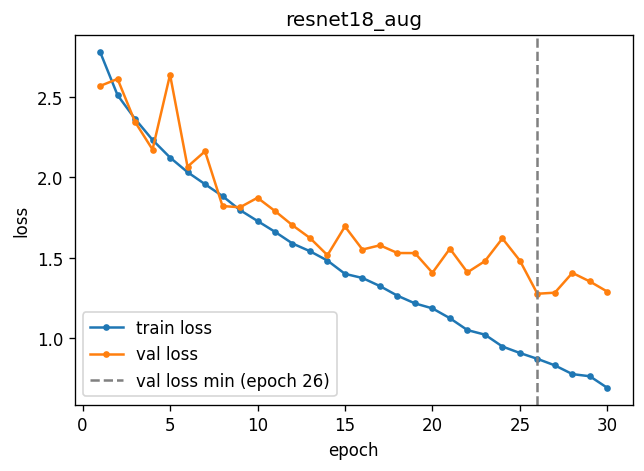

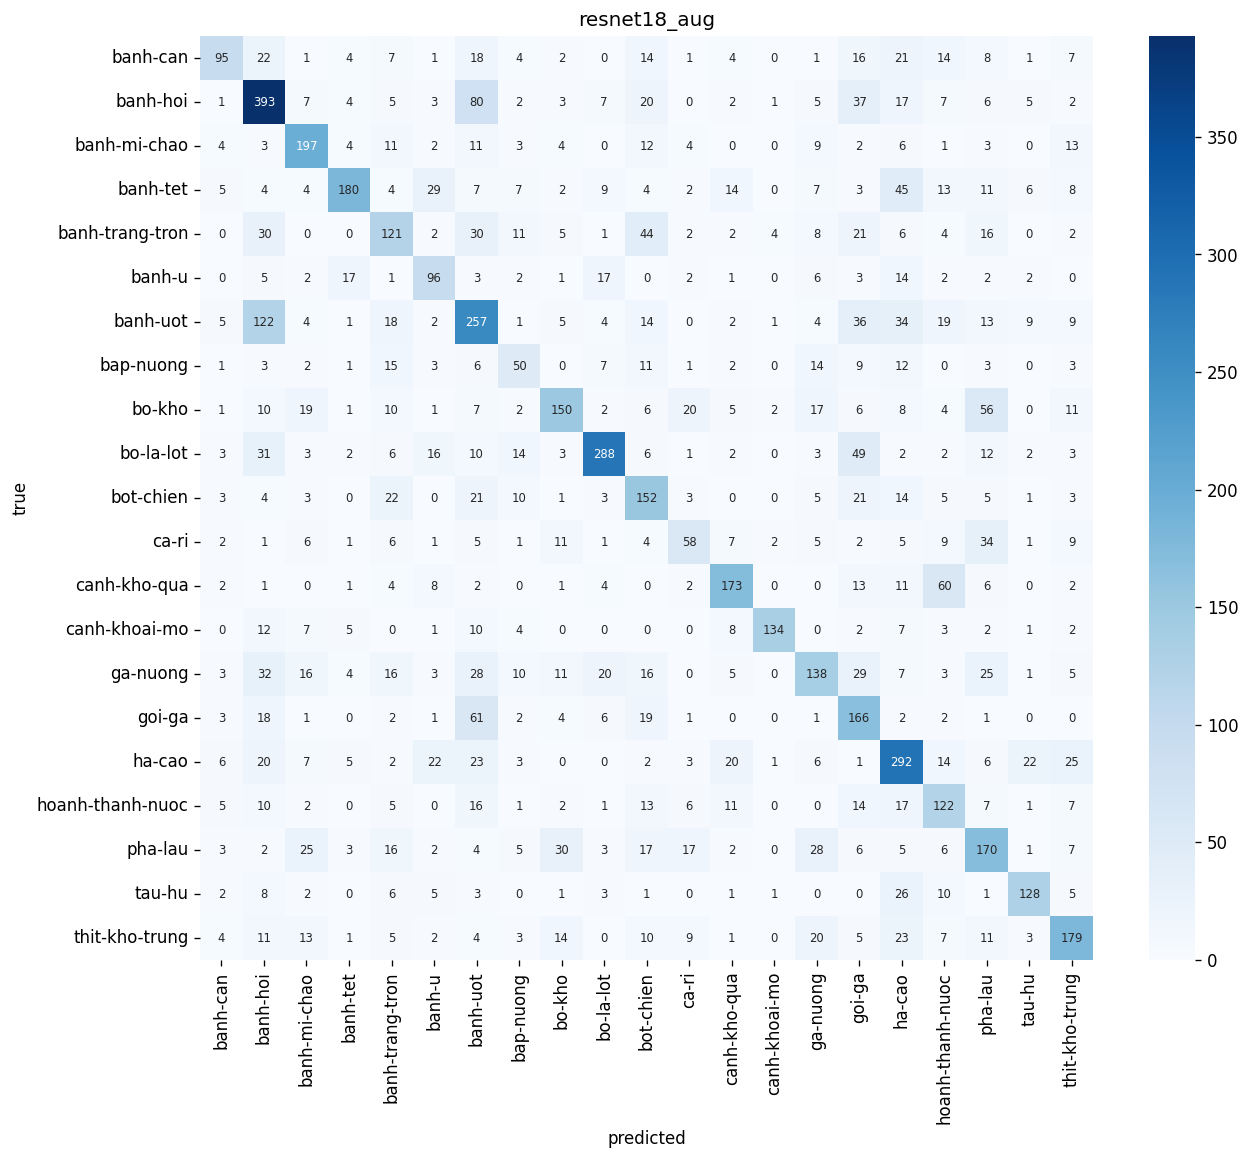

In [22]:
show("resnet18_aug")

In [23]:
run("resnet18_noaug", "--model resnet18 --no_aug --amp")

resnet18_noaug đã chạy rồi


params 11,187,285 | 21.1s/epoch | best epoch 29
accuracy 0.4572 | precision 0.4545 | recall 0.4341 | f1 0.4333


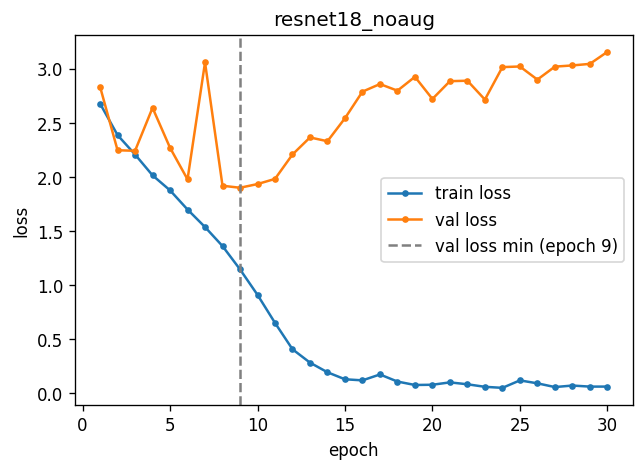

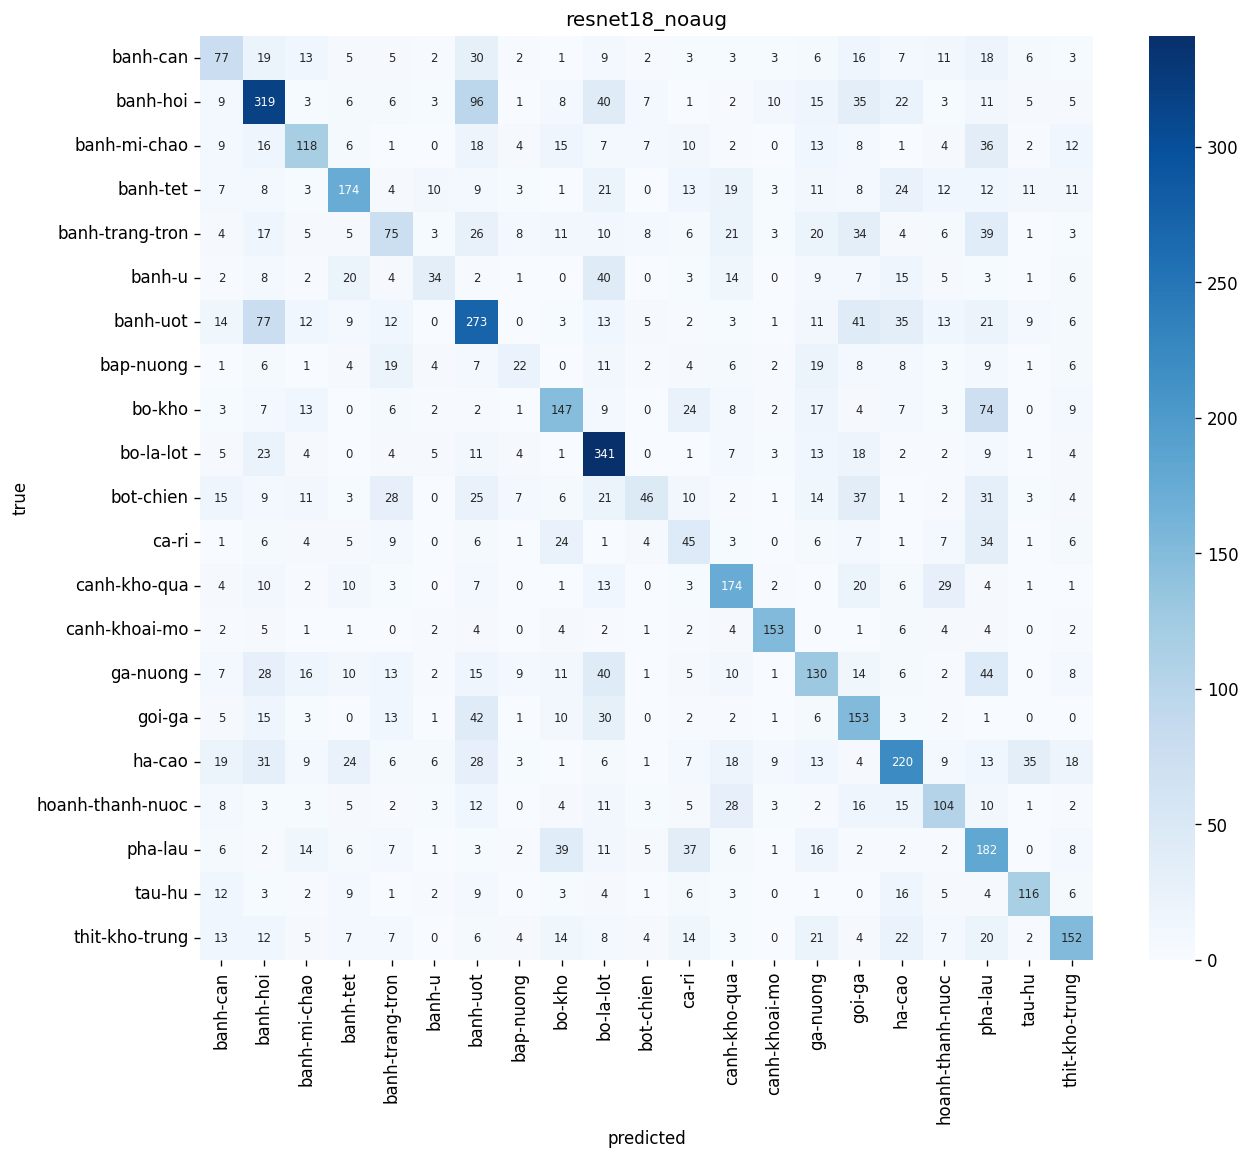

In [24]:
show("resnet18_noaug")

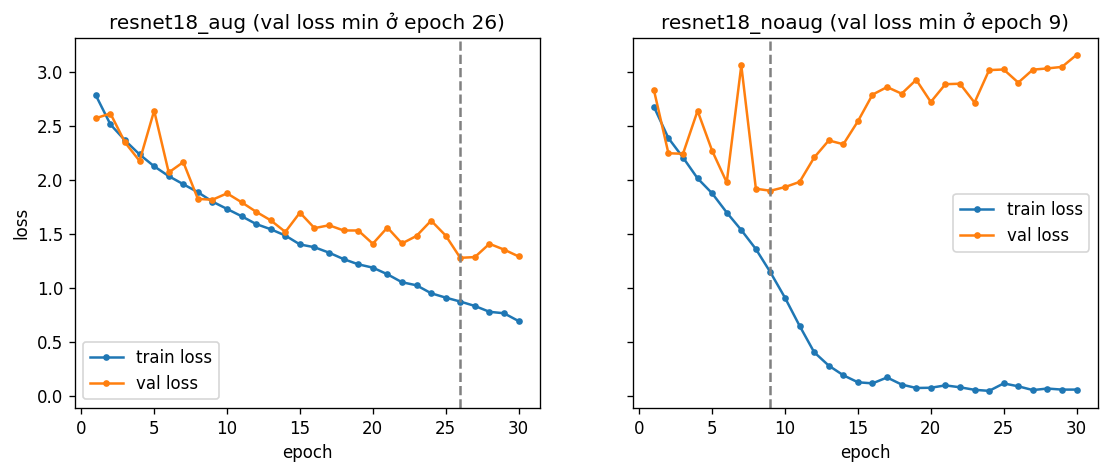

In [25]:
!python summary.py > /dev/null
display(Image("runs/resnet18_compare.png"))

Nhận xét:
- Số tham số 11,187,285, khớp với resnet18 của torchvision khi đổi fc sang 21 lớp.
- Có aug: accuracy 0.5296, macro-F1 0.5271. Không aug: accuracy 0.4572, macro-F1 0.4333 → có aug cao hơn 0.0938, 20/21 lớp tăng.
- Không aug: val loss thấp nhất ở epoch 9 (1.898), từ khoảng epoch 9-10 hai đường loss tách nhau rõ: train loss giảm gần về 0 (0.059 ở epoch 30, train acc 98%) còn val loss tăng lên 3.15, val acc đứng quanh 50% → overfit nặng, model học thuộc tập train. Val F1 vẫn dao động quanh 0.44-0.51 dù val loss tăng từ 1.9 lên 3.15: số ảnh đoán đúng gần như không đổi, nhưng các ảnh đoán sai thì model đoán rất tự tin nên loss tăng mạnh.
- Có aug: hai đường đi sát nhau tới khoảng epoch 15, sau đó khoảng cách mới tăng dần (epoch 30: train 0.69, val 1.29). Val loss thấp nhất ở epoch 26 (1.277) và nhìn chung vẫn đang giảm, train acc 77% → chưa overfit nặng, train thêm epoch có thể còn tăng.
- Giải thích: ResNet-18 có 11.2 triệu tham số mà chỉ có 9,040 ảnh train, gấp khoảng 29 lần LeNet, nên rất dễ học thuộc. Không aug thì mỗi epoch thấy lại đúng các ảnh cũ; có aug (cắt, lật, xoay, đổi sáng) thì mỗi epoch ảnh lại khác đi một chút, model phải học đặc trưng chung hơn. Đổi lại train chậm hơn (30.8 so với 21.1 s/epoch) và cần nhiều epoch hơn mới hội tụ.
- So với GoogLeNet (macro-F1 0.4142, khoảng 6.0 triệu tham số, ảnh 64x64), ResNet-18 nhiều tham số gấp khoảng 1.9 lần và dùng ảnh 112x112: không aug 0.4333 chỉ hơn 0.019, có aug 0.5271 thì hơn 0.113 → thêm tham số và ảnh to hơn mà không có augmentation thì gần như không giúp được gì vì model học thuộc tập train, phải có augmentation thì ResNet-18 mới hơn rõ.

## Bài 4. ResNet-50 pretrained

`microsoft/resnet-50`, bỏ classifier 1000 lớp, thay bằng `nn.Linear(2048, 21)`. Ảnh 224x224, mean/std của ImageNet, 10 epoch.
- Feature extraction: đóng băng backbone, chỉ học classifier, lr 1e-3
- Fine-tuning: học toàn bộ, lr 1e-4

In [32]:
run("resnet50_fe", "--model resnet50 --mode fe --amp")

resnet50_fe đã chạy rồi


params 23,551,061 | 49.2s/epoch | best epoch 10
accuracy 0.7264 | precision 0.7469 | recall 0.7327 | f1 0.7303


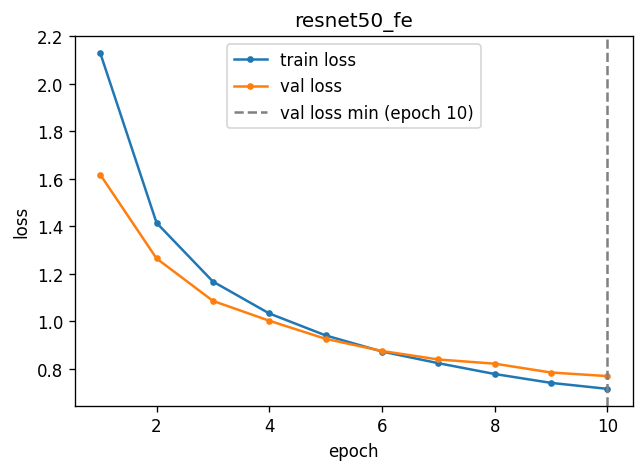

In [27]:
show("resnet50_fe")

In [33]:
run("resnet50_ft", "--model resnet50 --mode ft --amp")

resnet50_ft đã chạy rồi


params 23,551,061 | 64.2s/epoch | best epoch 8
accuracy 0.8456 | precision 0.8497 | recall 0.8447 | f1 0.8454


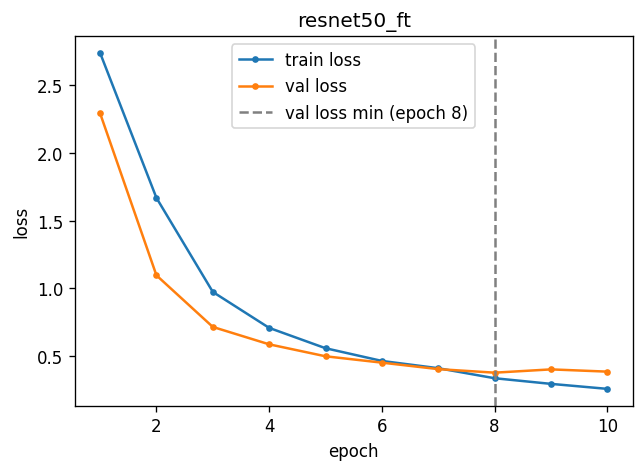

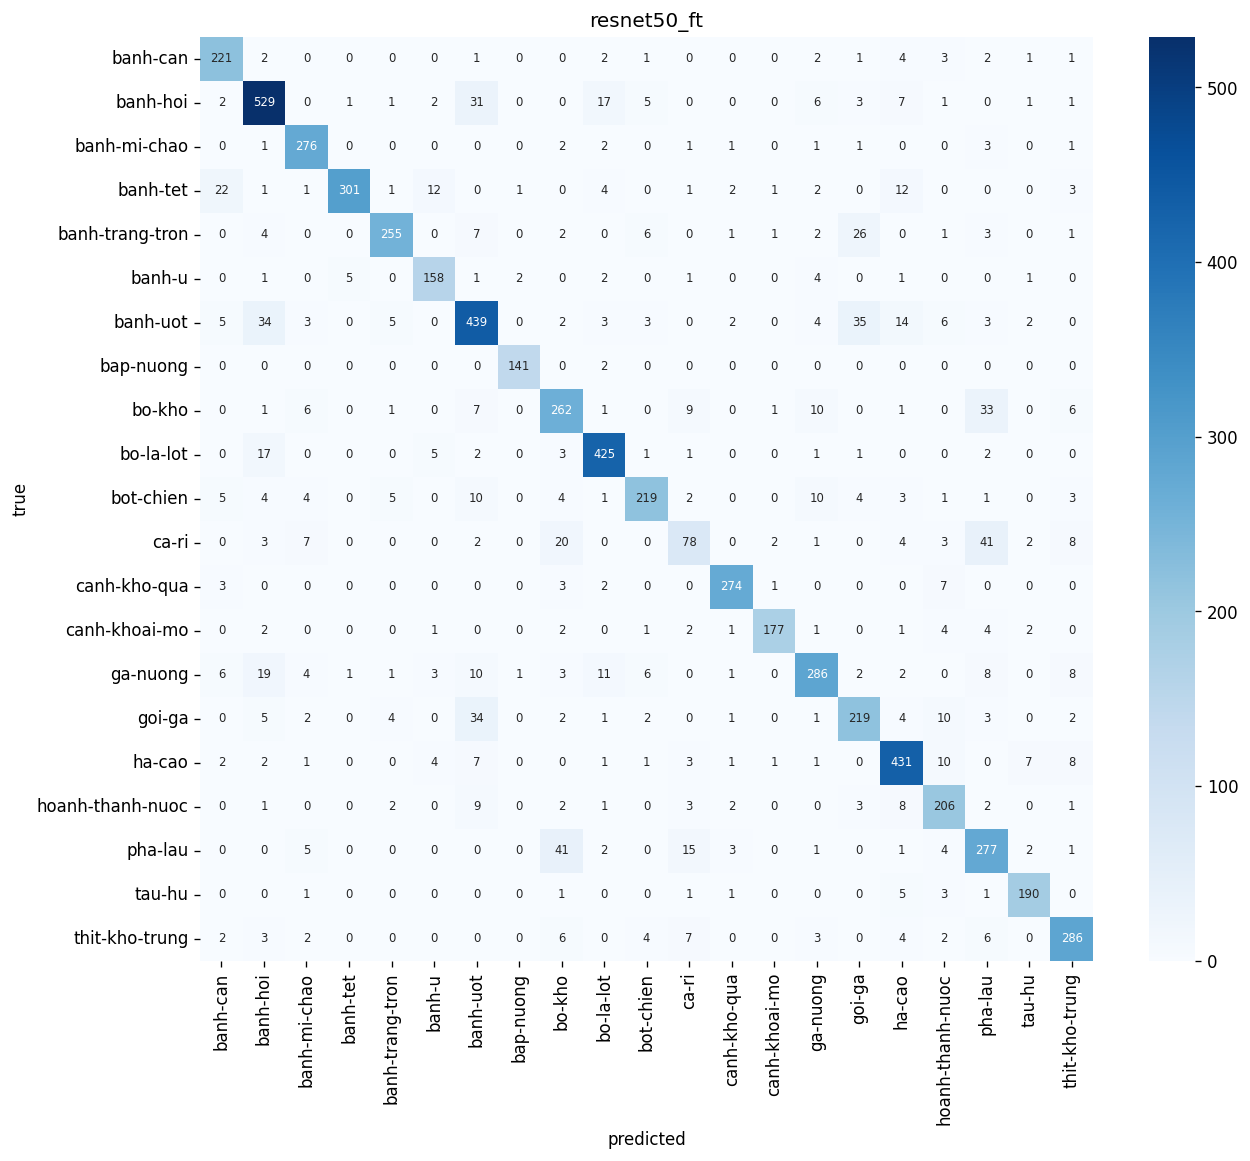

In [34]:
show("resnet50_ft")

Nhận xét:
- Feature extraction: accuracy 0.7264, macro-F1 0.7303, 49.2 s/epoch, chỉ học 43,029 tham số. Ngay epoch 1 val acc đã 60.6%, cao hơn hẳn LeNet sau 20 epoch, gần bằng ResNet-18 có aug sau 30 epoch (64.5%). Val loss tới epoch 10 vẫn còn giảm nên thêm epoch có thể còn tăng chút.
- Fine-tuning: accuracy 0.8456, macro-F1 0.8454, 64.2 s/epoch, cao hơn feature extraction 0.115 và cả 21 lớp đều tăng. Val loss thấp nhất ở epoch 8 (0.378) rồi nhích lên → bắt đầu overfit nhẹ, checkpoint lấy ở epoch 8.
- Feature extraction chỉ nhanh hơn fine-tuning khoảng 15 s/epoch vì vẫn phải forward qua toàn bộ backbone, chỉ bỏ được phần backward của backbone.
- So với ResNet-18 train từ đầu (có aug, 0.5271): fine-tuning cao hơn 0.318, feature extraction cao hơn 0.203. Lớp khó nhất vẫn là ca-ri (fine-tuning 0.529, feature extraction chỉ 0.287 với recall 0.187), hay bị nhầm sang bo-kho và pha-lau, ba món đều là thịt trong nước sốt màu nâu đỏ. bap-nuong từ 0.360 (ResNet-18) lên 0.979.
- Giải thích: backbone đã được train trên ImageNet (khoảng 1.2 triệu ảnh, 1000 lớp, có cả một số lớp đồ ăn) nên các đặc trưng từ cạnh, kết cấu tới hình dạng đã có sẵn, chỉ cần học thêm cách phân biệt 21 món. ResNet-18 từ đầu phải học mọi thứ từ khoảng 9 nghìn ảnh nên vừa chậm vừa overfit. Fine-tuning tốt hơn feature extraction vì các layer sâu được chỉnh lại theo ảnh món ăn Việt Nam, lr nhỏ (1e-4) nên không phá hỏng trọng số pretrained.

## Bảng tổng hợp

In [35]:
!python summary.py > /dev/null
from IPython.display import Markdown
display(Markdown(open("results.md").read()))

## Bảng tổng hợp (tập test)

| Mô hình | Resize | Tham số | Tham số học | Giây/epoch | Accuracy | Precision | Recall | macro-F1 |
|---|---|---|---|---|---|---|---|---|
| LeNet-5 (AvgPool) | 64x64 | 391,261 | 391,261 | 16.4 | 0.3252 | 0.3266 | 0.3146 | 0.3043 |
| LeNet-5 (MaxPool) | 64x64 | 391,261 | 391,261 | 16.6 | 0.3360 | 0.3264 | 0.3286 | 0.3127 |
| GoogLeNet | 64x64 | 6,002,357 | 6,002,357 | 25.5 | 0.4442 | 0.4538 | 0.4210 | 0.4142 |
| ResNet-18 từ đầu (có aug) | 112x112 | 11,187,285 | 11,187,285 | 30.8 | 0.5296 | 0.5502 | 0.5202 | 0.5271 |
| ResNet-18 từ đầu (không aug) | 112x112 | 11,187,285 | 11,187,285 | 21.1 | 0.4572 | 0.4545 | 0.4341 | 0.4333 |
| ResNet-50 pretrained (feature extraction) | 224x224 | 23,551,061 | 43,029 | 49.2 | 0.7264 | 0.7469 | 0.7327 | 0.7303 |
| ResNet-50 pretrained (fine-tuning) | 224x224 | 23,551,061 | 23,551,061 | 64.2 | 0.8456 | 0.8497 | 0.8447 | 0.8454 |

## So sánh macro-F1

- lenet_max vs lenet_avg: 0.3127 vs 0.3043 (chênh +0.0084)
- googlenet vs lenet_avg: 0.4142 vs 0.3043 (chênh +0.1100)
- resnet18_aug vs resnet18_noaug: 0.5271 vs 0.4333 (chênh +0.0938)
- resnet50_ft vs resnet50_fe: 0.8454 vs 0.7303 (chênh +0.1151)
- resnet50_ft vs resnet18_aug: 0.8454 vs 0.5271 (chênh +0.3183)

## Epoch val loss thấp nhất

| Run | Epoch | val loss min | val loss cuối |
|---|---|---|---|
| lenet_avg | 19 | 2.0093 | 2.0511 |
| lenet_max | 20 | 1.9297 | 1.9297 |
| googlenet | 19 | 1.6528 | 1.6852 |
| resnet18_aug | 26 | 1.2773 | 1.2903 |
| resnet18_noaug | 9 | 1.8976 | 3.1543 |
| resnet50_fe | 10 | 0.7685 | 0.7685 |
| resnet50_ft | 8 | 0.3778 | 0.3854 |

## F1 từng lớp

| Lớp | lenet_avg | lenet_max | googlenet | resnet18_aug | resnet18_noaug | resnet50_fe | resnet50_ft |
|---|---|---|---|---|---|---|---|
| banh-can | 0.192 | 0.182 | 0.333 | 0.488 | 0.332 | 0.767 | 0.868 |
| banh-hoi | 0.400 | 0.392 | 0.548 | 0.583 | 0.518 | 0.648 | 0.856 |
| banh-mi-chao | 0.375 | 0.302 | 0.432 | 0.646 | 0.443 | 0.801 | 0.918 |
| banh-tet | 0.312 | 0.262 | 0.493 | 0.602 | 0.517 | 0.820 | 0.896 |
| banh-trang-tron | 0.174 | 0.132 | 0.263 | 0.409 | 0.281 | 0.761 | 0.873 |
| banh-u | 0.186 | 0.286 | 0.372 | 0.511 | 0.266 | 0.810 | 0.875 |
| banh-uot | 0.292 | 0.304 | 0.303 | 0.441 | 0.458 | 0.605 | 0.784 |
| bap-nuong | 0.142 | 0.172 | 0.108 | 0.360 | 0.204 | 0.958 | 0.979 |
| bo-kho | 0.321 | 0.355 | 0.515 | 0.510 | 0.458 | 0.617 | 0.756 |
| bo-la-lot | 0.524 | 0.530 | 0.649 | 0.691 | 0.617 | 0.782 | 0.909 |
| bot-chien | 0.237 | 0.305 | 0.369 | 0.474 | 0.247 | 0.663 | 0.834 |
| ca-ri | 0.175 | 0.132 | 0.148 | 0.383 | 0.241 | 0.287 | 0.529 |
| canh-kho-qua | 0.466 | 0.510 | 0.544 | 0.627 | 0.554 | 0.789 | 0.945 |
| canh-khoai-mo | 0.751 | 0.687 | 0.780 | 0.779 | 0.773 | 0.877 | 0.927 |
| ga-nuong | 0.249 | 0.251 | 0.402 | 0.425 | 0.364 | 0.749 | 0.808 |
| goi-ga | 0.207 | 0.191 | 0.363 | 0.454 | 0.421 | 0.608 | 0.749 |
| ha-cao | 0.249 | 0.323 | 0.407 | 0.554 | 0.487 | 0.814 | 0.878 |
| hoanh-thanh-nuoc | 0.235 | 0.255 | 0.306 | 0.446 | 0.438 | 0.727 | 0.822 |
| pha-lau | 0.283 | 0.303 | 0.366 | 0.453 | 0.391 | 0.662 | 0.748 |
| tau-hu | 0.398 | 0.448 | 0.542 | 0.661 | 0.582 | 0.861 | 0.925 |
| thit-kho-trung | 0.222 | 0.246 | 0.456 | 0.571 | 0.509 | 0.731 | 0.873 |


Kết luận:
- Ảnh hưởng của kiến trúc (cùng dữ liệu, cùng phép chia, cùng seed): macro-F1 tăng từ LeNet 0.3043 → GoogLeNet 0.4142 → ResNet-18 có aug 0.5271. Mạng sâu hơn, nhiều filter hơn thì tốt hơn, nhưng ResNet-18 chỉ hơn rõ GoogLeNet khi có augmentation (không aug thì 0.4333, chỉ hơn GoogLeNet 0.019). Một phần chênh lệch cũng do ResNet-18 dùng ảnh 112x112 còn hai model kia dùng 64x64.
- Ảnh hưởng của transfer learning: ResNet-50 pretrained vượt hẳn 3 model train từ đầu, feature extraction 0.7303 và fine-tuning 0.8454 chỉ sau 10 epoch, gần gấp 3 lần LeNet AvgPool (0.3043) và hơn ResNet-18 từ đầu 0.318. Với tập dữ liệu khoảng 10 nghìn ảnh như VinaFood21, dùng model pretrained hợp lý hơn nhiều so với train từ đầu.
- macro-F1 trên test luôn thấp hơn trên val, ví dụ ResNet-18 có aug 0.623 (val) so với 0.527 (test), ResNet-50 fine-tuning 0.871 so với 0.845. Tập val được tách từ chính tập train nên giống train hơn tập test, cộng thêm việc chọn checkpoint theo val. Chênh lệch nhỏ nhất ở ResNet-50 pretrained, cho thấy model này tổng quát tốt hơn.
- Cặp banh-hoi / banh-uot bị nhầm nhiều ở hầu hết các model; tới ResNet-50 fine-tuning thì nhầm lẫn chủ yếu chuyển sang nhóm ca-ri, pha-lau, bo-kho.

## Tải kết quả về để push lên github

In [36]:
!zip -qr ket_qua.zip runs splits results.md -x "*.pt" "*.tmp"
from google.colab import files
files.download("ket_qua.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>